In [1]:
!nvidia-smi

Fri Oct 30 13:09:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   45C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install ultralytics roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 105.4 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [3]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace("lab-yz5eb").project("cottonweeddet12")
version = project.version(1)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to CottonWeedDet12-1 in yolov8:: 100%|██████████| 11308/11308 [00:01<00:00, 6938.66it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
import os, yaml
from collections import Counter

with open(f"{dataset.location}/data.yaml") as f:
    config = yaml.safe_load(f)
nomes = config["names"]
print("Classes:", len(nomes))

for split in ["train", "valid", "test"]:
    pasta = f"{dataset.location}/{split}/labels"
    if not os.path.exists(pasta):
        continue
    contagem = Counter()
    arquivos = os.listdir(pasta)
    for arq in arquivos:
        with open(os.path.join(pasta, arq)) as f:
            for linha in f:
                if linha.strip():
                    contagem[int(linha.split()[0])] += 1
    print(f"\n{split}: {len(arquivos)} imagens")
    for i, n in sorted(contagem.items()):
        print(f"  {nomes[i]}: {n} caixas")

Classes: 12

train: 3954 imagens
  weed- amaranthus palmeri: 229 caixas
  weed- amaranthus tuberculatus: 1394 caixas
  weed- ambrosia artemisiifolia: 641 caixas
  weed- eclipta: 605 caixas
  weed- eleusine indica: 145 caixas
  weed- euphorbia maculata: 689 caixas
  weed- ipomoea indica: 916 caixas
  weed- mollugo verticillata: 638 caixas
  weed- physalis angulata: 91 caixas
  weed- portulaca oleracea: 743 caixas
  weed- senna obtusifolia: 160 caixas
  weed- sida rhombifolia: 339 caixas

valid: 1129 imagens
  weed- amaranthus palmeri: 82 caixas
  weed- amaranthus tuberculatus: 383 caixas
  weed- ambrosia artemisiifolia: 161 caixas
  weed- eclipta: 189 caixas
  weed- eleusine indica: 41 caixas
  weed- euphorbia maculata: 181 caixas
  weed- ipomoea indica: 286 caixas
  weed- mollugo verticillata: 212 caixas
  weed- physalis angulata: 16 caixas
  weed- portulaca oleracea: 159 caixas
  weed- senna obtusifolia: 57 caixas
  weed- sida rhombifolia: 107 caixas

test: 565 imagens
  weed- amarant

In [5]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### Explicação dos Parâmetros de Treinamento

- **`epochs=60`**: O modelo vê o dataset inteiro 60 vezes durante o treinamento.
- **`imgsz=640`**: As imagens são redimensionadas para 640 pixels, o tamanho padrão recomendado pelo YOLO.
- **`batch=32`**: Processamento de 32 imagens por vez (lote). A GPU NVIDIA L4 suporta essa quantidade com folga.
- **`patience=15`**: Se o desempenho do modelo não melhorar por 15 épocas consecutivas, o treinamento é interrompido antecipadamente (Early Stopping). Isso economiza tempo e evita o *overfitting*.
- **`project`**: Salva todos os pesos (`.pt`), gráficos e resultados diretamente na sua pasta do Google Drive para que não sejam perdidos ao encerrar a sessão.

In [6]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

resultados = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=60,
    imgsz=640,
    batch=32,
    patience=15,
    project="/content/drive/MyDrive/weeddetect-ai/runs",
    name="yolo11s_cottonweed",
)

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/CottonWeedDet12-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_cottonweed, nbs=64, nms=None, opset=None, op

### Explicação da Validação Final (Conjunto de Teste)

- **`best = YOLO(...)`**: Carrega o melhor modelo salvo durante o treinamento (`best.pt`). Ele recupera automaticamente os pesos da época que obteve o melhor desempenho na validação.
- **`split="test"`**: Define que a validação será feita especificamente sobre o conjunto de dados de **teste** (dados inéditos que o modelo nunca viu durante o treino e nem durante os ajustes de validação periódicos).
- **`project` e `name`**: Define o diretório de destino no seu Drive (`teste_final`) para salvar os relatórios de métricas, matriz de confusão, curvas de precisão-revocação (PR Curve) e imagens com as predições de teste anotadas.

In [7]:
best = YOLO("/content/drive/MyDrive/weeddetect-ai/runs/yolo11s_cottonweed/weights/best.pt")

metricas_teste = best.val(
    data=f"{dataset.location}/data.yaml",
    split="test",
    project="/content/drive/MyDrive/weeddetect-ai/runs",
    name="teste_final",
)

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s summary (fused): 100 layers, 9,417,444 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2130.9±778.6 MB/s, size: 114.4 KB)
val: Scanning /content/CottonWeedDet12-1/test/labels... 565 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 565/565 1.5Kit/s 0.4s
val: New cache created: /content/CottonWeedDet12-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 5.8it/s 6.3s
                   all        565        924      0.927      0.849      0.902      0.838
weed- amaranthus palmeri         33         37      0.888      0.892      0.956      0.927
weed- amaranthus tuberculatus        135        182      0.948      0.908      0.972       0.94
weed- ambrosia artemisiifolia         50         94      0.898      0.904       0.95      0.863
         weed- eclipta         47         71

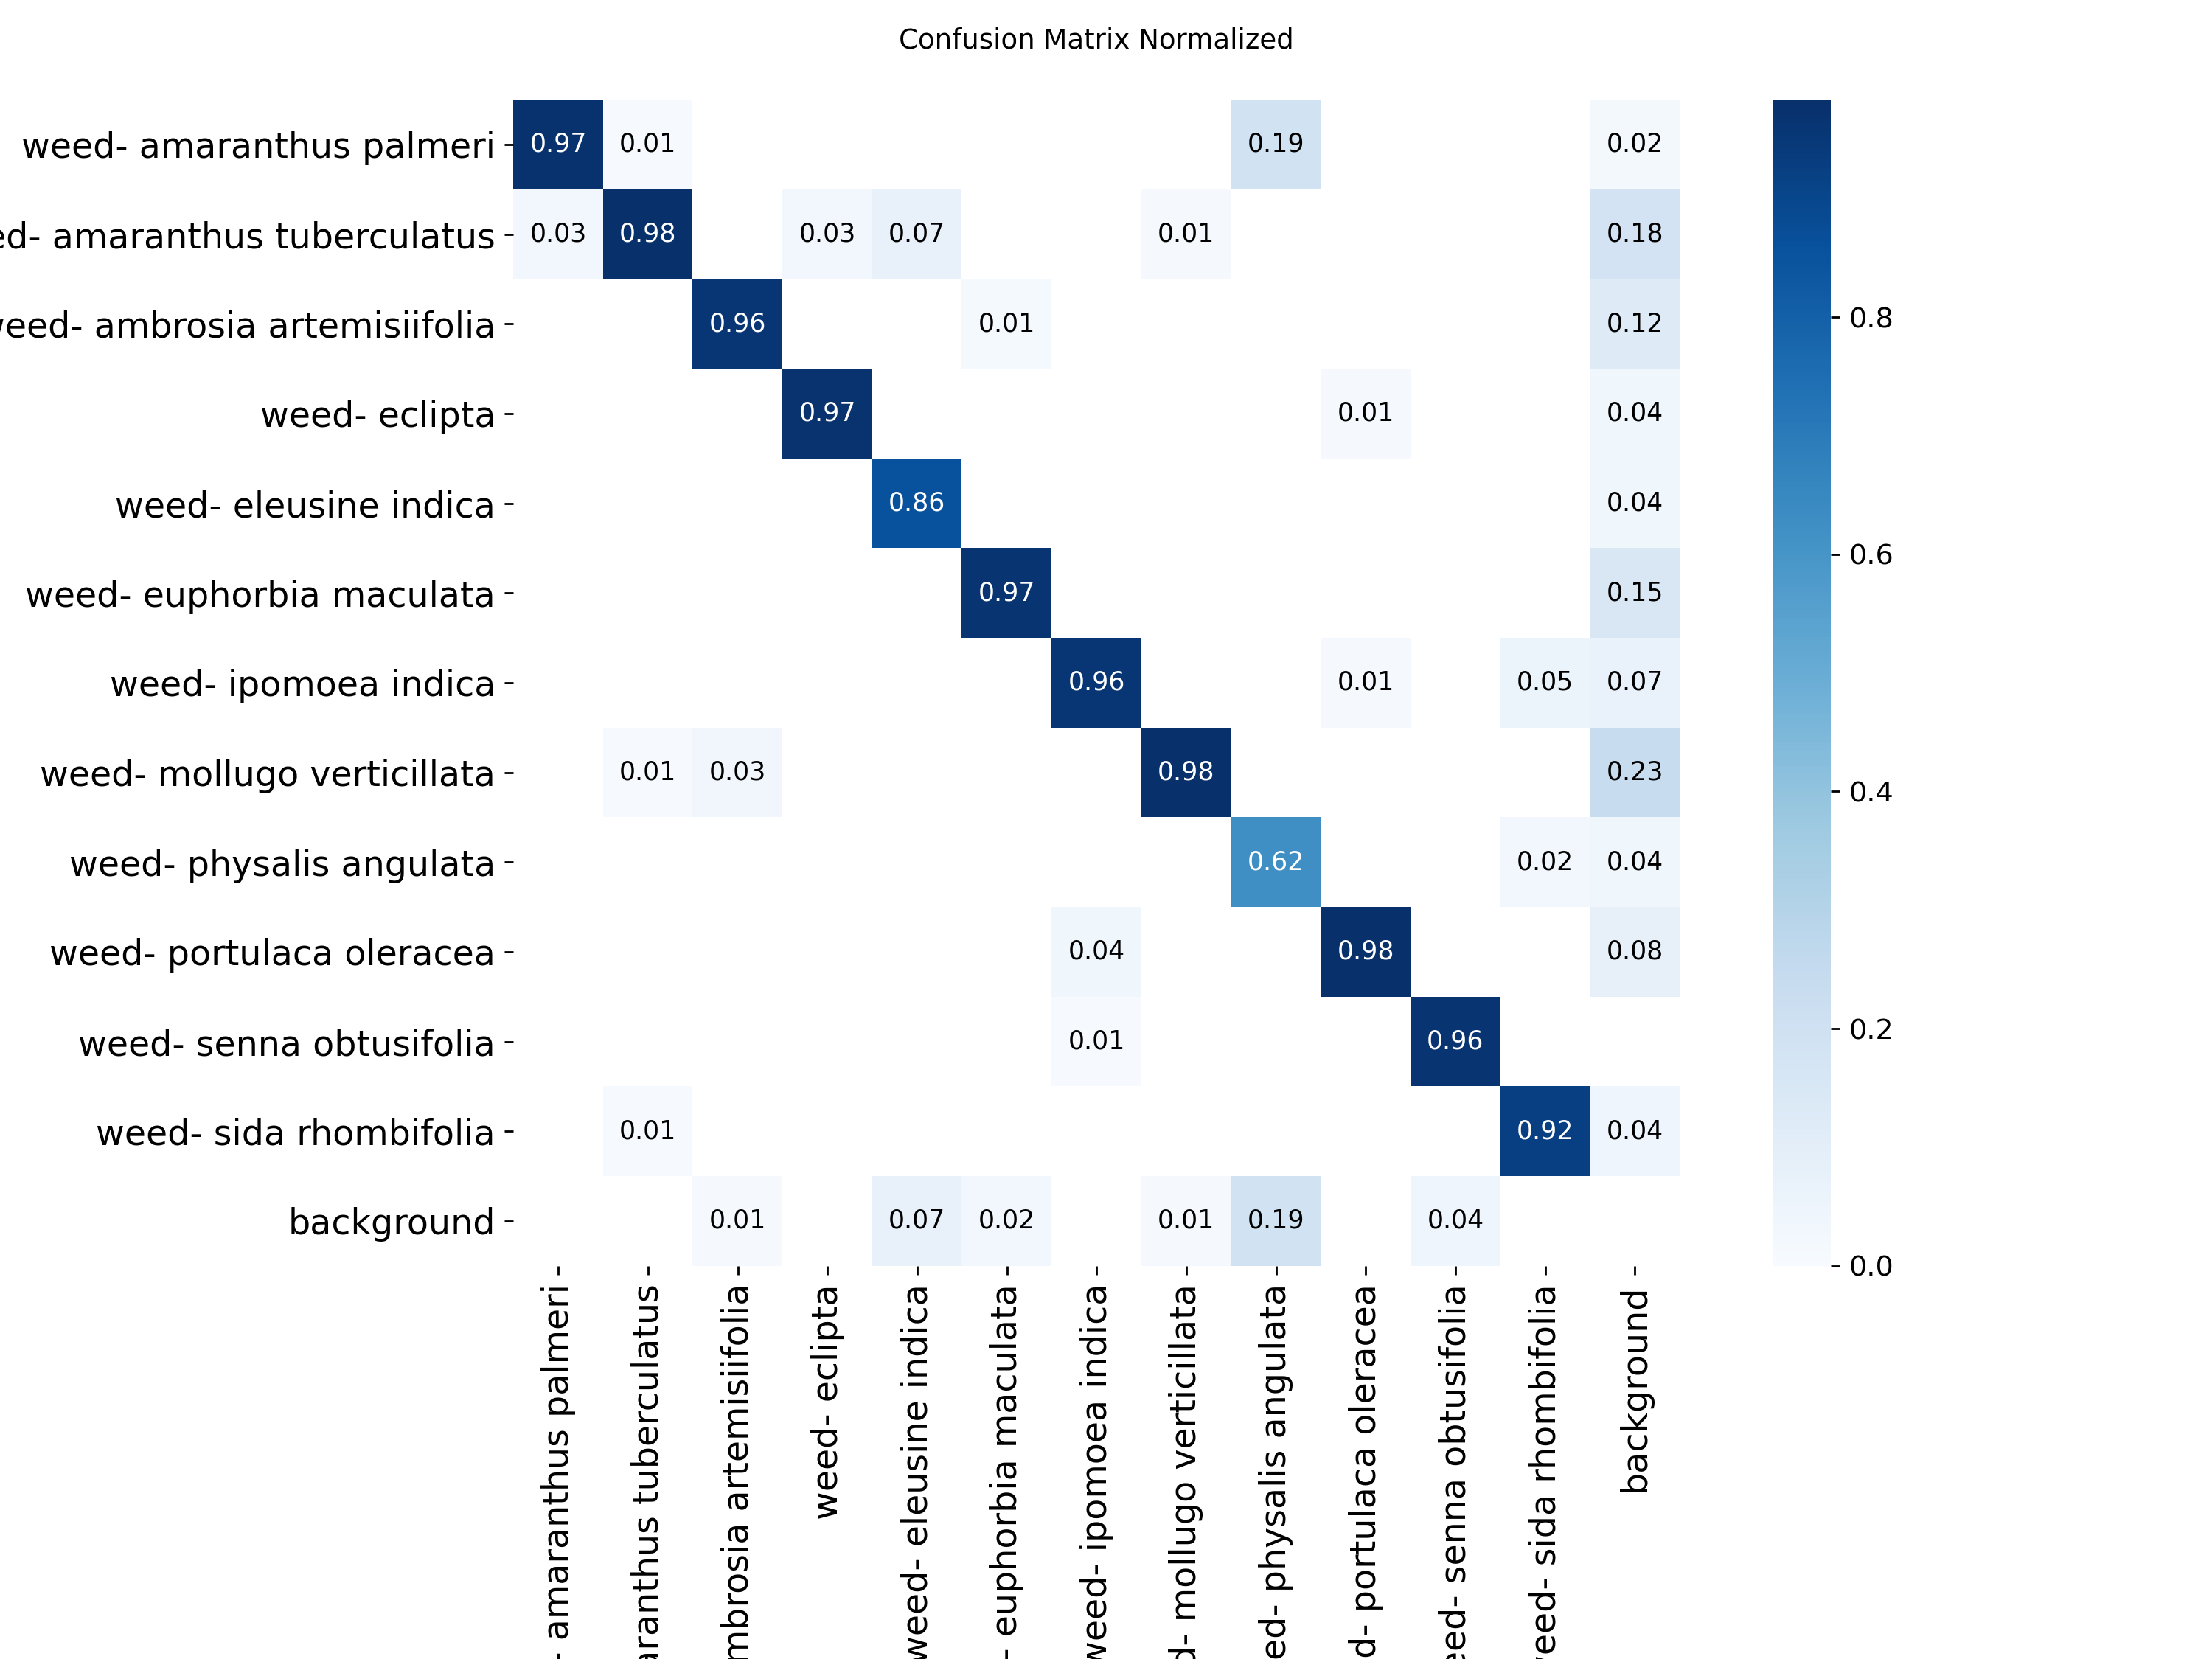

In [8]:
from IPython.display import Image
Image("/content/drive/MyDrive/weeddetect-ai/runs/teste_final/confusion_matrix_normalized.png", width=900)

In [ ]:
from IPython.display import Image
Image("/content/drive/MyDrive/weeddetect-ai/runs/teste_final/.png", width=900)